# Minnie and V1DD nuclei in CCF space

Overlay randomly sampled Minnie 1822 and V1DD 1196 nucleus positions in the XY, YZ, and XZ planes of CCFv3. These are projections of the same sampled 3D points, not anatomical slices.

First run the base EM ETLs and then [Minnie CCF ETL](../ETL/EM/etl_minnie1822_03_ccf_coord.ipynb) and [V1DD CCF ETL](../ETL/EM/etl_v1dd1196_02_ccf_coord.ipynb), using the same configured output root. This notebook reads their stored `ccfv3_um` SOMA locations and does not transform coordinates or modify CCM tables.

Sample without replacement up to 5,000 nuclei per dataset with seed 42. Each dataset keeps its own cohort; the two projects' cell IDs are not intersected. The same samples, dataset colors, and per-coordinate limits are used in all panels.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from connects_common_connectivity.config import get_settings
from connects_common_connectivity.io import read_reference_spaces, read_spatial_locations
from connects_common_connectivity.io.path_spec import MODEL_TABLE_PATHS
from connects_common_connectivity.models import LocationType, SignedAxis, Unit

In [2]:
OUTPUT_ROOT = Path(get_settings().output_root)
CCF_REFERENCE_SPACE_ID = "ccfv3_um"
SAMPLE_SIZE = 5_000
RANDOM_STATE = 42
DATASETS = {
    "minnie65": "Minnie 1822",
    "v1dd_1196": "V1DD 1196",
}
COLORS = {"minnie65": "tab:blue", "v1dd_1196": "tab:orange"}
EXPECTED_ORIENTATION = {
    "anterior_to_posterior": SignedAxis.PLUS_X.value,
    "dorsal_to_ventral": SignedAxis.PLUS_Y.value,
    "subject_left_to_right": SignedAxis.PLUS_Z.value,
}
AXIS_LABELS = {
    "x": r"X: anterior $\rightarrow$ posterior ($\mu$m)",
    "y": r"Y: dorsal $\rightarrow$ ventral ($\mu$m)",
    "z": r"Z: subject left $\rightarrow$ right ($\mu$m)",
}
assert isinstance(SAMPLE_SIZE, int) and SAMPLE_SIZE > 0, (
    "SAMPLE_SIZE must be a positive integer."
)
missing_paths = [
    OUTPUT_ROOT / MODEL_TABLE_PATHS[table]
    for table in ("ReferenceSpace", "SpatialLocation")
    if not (OUTPUT_ROOT / MODEL_TABLE_PATHS[table]).is_dir()
]
assert not missing_paths, (
    f"Missing CCM tables: {missing_paths}. Run both EM CCF ETL notebooks first."
)

## read and sample stored nuclei

Require micrometer units and matching anatomical directions in both project-scoped reference spaces. Missing, duplicate, or non-finite coordinates raise errors rather than being silently dropped. Sort cell IDs before sampling so the seed is reproducible even if table row order changes.

In [3]:
sampled_by_project = {}
for project_id, label in DATASETS.items():
    spaces = read_reference_spaces(
        project_id=project_id,
        reference_space_ids=CCF_REFERENCE_SPACE_ID,
        output_root=OUTPUT_ROOT,
    )
    assert spaces.height == 1, (
        f"Expected one CCF reference space for {label}; run its CCF ETL first."
    )
    space = spaces.row(0, named=True)
    assert space["unit"] == Unit.MICRONS_LENGTH.value, (
        f"Expected CCF micrometer units for {label}."
    )
    orientation = space["anatomical_orientation"]
    assert orientation is not None, f"Missing anatomical orientation for {label}."
    for direction, signed_axis in EXPECTED_ORIENTATION.items():
        assert orientation[direction] == signed_axis, (
            f"Unexpected {direction} axis for {label}."
        )

    locations = read_spatial_locations(
        project_id,
        reference_spaces=CCF_REFERENCE_SPACE_ID,
        location_types=LocationType.SOMA,
        output_root=OUTPUT_ROOT,
    ).select("dataitem_id", "x", "y", "z").sort("dataitem_id")
    assert locations.height > 0, f"No CCF nuclei for {label}; run its CCF ETL first."
    assert locations["dataitem_id"].null_count() == 0, f"Null cell IDs for {label}."
    assert locations["dataitem_id"].n_unique() == locations.height, (
        f"Duplicate CCF nuclei for {label}."
    )
    assert np.isfinite(locations.select("x", "y", "z").to_numpy()).all(), (
        f"Missing or non-finite CCF coordinates for {label}."
    )
    sample = locations.sample(
        n=min(SAMPLE_SIZE, locations.height),
        with_replacement=False,
        shuffle=True,
        seed=RANDOM_STATE,
    )
    sampled_by_project[project_id] = sample
    print(f"{label}: {locations.height:,} stored nuclei; {sample.height:,} sampled")

combined_sample = pl.concat(list(sampled_by_project.values()))
axis_limits = {}
for coordinate in ("x", "y", "z"):
    values = combined_sample[coordinate].to_numpy()
    lower, upper = values.min(), values.max()
    padding = max((upper - lower) * 0.05, 1.0)
    axis_limits[coordinate] = (lower - padding, upper + padding)

Minnie 1822: 81,059 stored nuclei; 5,000 sampled
V1DD 1196: 63,986 stored nuclei; 5,000 sampled


## XY, YZ, and XZ overlays

Increasing X points anterior to posterior, Y dorsal to ventral, and Z subject left to right. Labels describe increasing coordinate values, not the viewer's left/right. The XY panel inverts its display Y axis to place dorsal above ventral; the coordinate values themselves remain unchanged. Every panel uses equal physical scaling on both axes.

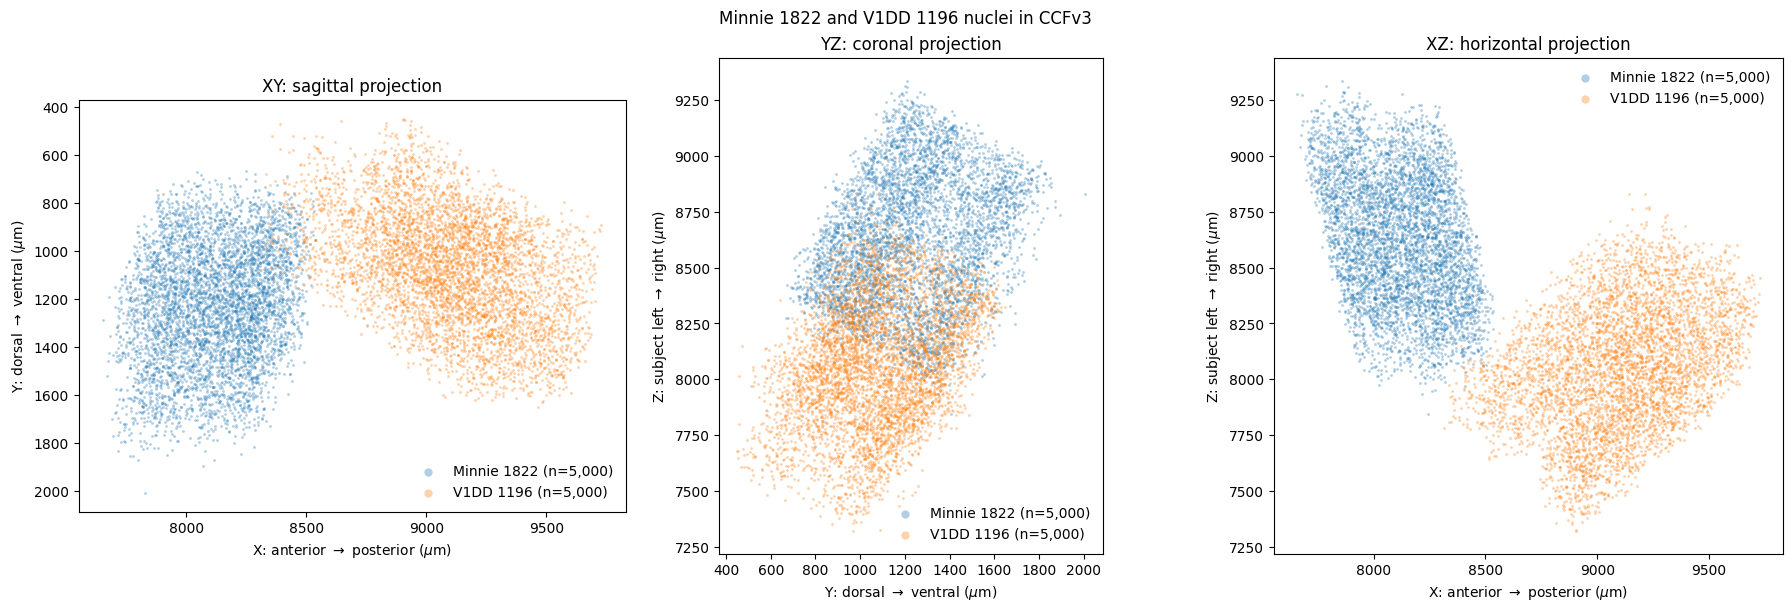

In [4]:
planes = (
    ("x", "y", "XY: sagittal projection"),
    ("y", "z", "YZ: coronal projection"),
    ("x", "z", "XZ: horizontal projection"),
)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, (horizontal, vertical, title) in zip(axes, planes):
    for project_id, label in DATASETS.items():
        sample = sampled_by_project[project_id]
        ax.scatter(
            sample[horizontal].to_numpy(),
            sample[vertical].to_numpy(),
            s=4,
            alpha=0.35,
            color=COLORS[project_id],
            label=f"{label} (n={sample.height:,})",
            linewidths=0,
            rasterized=True,
        )
    ax.set_title(title)
    ax.set_xlabel(AXIS_LABELS[horizontal])
    ax.set_ylabel(AXIS_LABELS[vertical])
    ax.set_xlim(axis_limits[horizontal])
    ax.set_ylim(axis_limits[vertical])
    if vertical == "y":
        ax.invert_yaxis()
    ax.set_aspect("equal", adjustable="box")
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.legend(markerscale=3, frameon=False)
fig.suptitle("Minnie 1822 and V1DD 1196 nuclei in CCFv3")
plt.show()

## Neuroglancer sanity check against Casey's boxes

Reuse exactly the nuclei in `sampled_by_project` from the plots above. Read [Casey's original view](https://spelunker.cave-explorer.org/#!middleauth+https://global.daf-apis.com/nglstate/api/v1/4525104734666752), deep-copy its state, and append one point-annotation layer per dataset. Keep every original layer and the original camera unchanged. Coordinates are already CCF micrometers: do not apply the affine again or use the plotting axis inversion.

The boxes in this state are the transformed segmentation-volume bounds in `seg65` and `v1dd_seg`, not separate hand-drawn annotations. The numerical check below uses those exact sources, not the larger imagery bounds or the CCF-aligned bounding envelope of a rotated volume.

CAVE authentication is needed for both servers. If necessary, run these commands **in a terminal**, paste tokens only into the hidden prompts, and choose `exit` at the datastack-selection prompt:

```bash
uv run --no-sync python -c "from caveclient import CAVEclient; CAVEclient.setup_token('https://global.daf-apis.com', open=False)"
uv run --no-sync python -c "from caveclient import CAVEclient; CAVEclient.setup_token('https://global.em.brain.allentech.org', open=False)"
```

Only the final publish cell uploads data: it creates a **new state and link** containing the sampled coordinates and cell IDs. No cell updates Casey's state or any CCM table.

In [5]:
import json
from copy import deepcopy

import requests
from caveclient import CAVEclient
from IPython.display import Markdown, display
from matplotlib.colors import to_hex

CASEY_STATE_ID = 4525104734666752
STATE_SERVER = "https://global.daf-apis.com"
VIEWER_URL = "https://spelunker.cave-explorer.org/"
CCF_DIMENSIONS = {axis: [1e-6, "m"] for axis in ("x", "y", "z")}
BOX_SOURCES = {
    "minnie65": {
        "layer": "seg65",
        "url": "graphene://middleauth+https://minnie.microns-daf.com/segmentation/table/minnie3_v1",
        "auth_server": "https://global.daf-apis.com",
    },
    "v1dd_1196": {
        "layer": "v1dd_seg",
        "url": "graphene://middleauth+https://api.em.brain.allentech.org/segmentation/table/aibs_v1dd",
        "auth_server": "https://global.em.brain.allentech.org",
    },
}
BOUNDARY_TOLERANCE_UM = 1e-6

state_client = CAVEclient(server_address=STATE_SERVER, max_retries=0).state
casey_state = state_client.get_state_json(CASEY_STATE_ID)
casey_snapshot = json.dumps(casey_state, sort_keys=True)
assert list(casey_state["dimensions"]) == ["x", "y", "z"], (
    "Casey's state no longer uses XYZ axis order."
)
assert casey_state["dimensions"] == CCF_DIMENSIONS, (
    "Casey's state no longer uses CCF micrometer dimensions."
)
assert set(sampled_by_project) == set(BOX_SOURCES), "Expected both EM samples."
print(f"Read original state {CASEY_STATE_ID}; no state has been uploaded or modified.")

Read original state 4525104734666752; no state has been uploaded or modified.


### Copy the view and add CCF point layers

Local annotation sources explicitly declare one micrometer per coordinate unit. Colors match the scatter plots, and point descriptions retain the dataset and cell ID. All sampled points are included, even if the containment check later flags them as outside.

In [6]:
new_state = deepcopy(casey_state)
new_state["title"] = "Minnie 1822 and V1DD 1196 CCF nuclei: box sanity check"
original_layer_count = len(casey_state["layers"])
existing_names = {layer["name"] for layer in casey_state["layers"]}
annotation_layers = []
for project_id, label in DATASETS.items():
    sample = sampled_by_project[project_id]
    layer_name = f"{label} sampled CCF nuclei"
    assert layer_name not in existing_names, f"Layer already exists: {layer_name}"
    assert sample.height > 0, f"No sampled nuclei for {label}."
    assert sample["dataitem_id"].null_count() == 0, f"Null sampled IDs for {label}."
    assert sample["dataitem_id"].n_unique() == sample.height, (
        f"Duplicate sampled IDs for {label}."
    )
    assert np.isfinite(sample.select("x", "y", "z").to_numpy()).all(), (
        f"Non-finite sampled coordinates for {label}."
    )
    annotation_layers.append({
        "name": layer_name,
        "type": "annotation",
        "visible": True,
        "source": {
            "url": "local://annotations",
            "transform": {"outputDimensions": deepcopy(CCF_DIMENSIONS)},
        },
        "annotationColor": to_hex(COLORS[project_id]),
        "annotations": [
            {
                "id": f"{project_id}:{row['dataitem_id']}",
                "type": "point",
                "point": [row["x"], row["y"], row["z"]],
                "description": f"{label}; dataitem_id={row['dataitem_id']}",
            }
            for row in sample.iter_rows(named=True)
        ],
    })
new_state["layers"].extend(annotation_layers)
assert new_state["layers"][:original_layer_count] == casey_state["layers"]
assert json.dumps(casey_state, sort_keys=True) == casey_snapshot
print(f"Prepared {sum(len(layer['annotations']) for layer in annotation_layers):,} points.")

Prepared 10,000 points.


### Count sampled nuclei inside each dataset's exact box

Read the finest-scale `resolution`, `voxel_offset`, and `size` from each segmentation source's `/info` metadata. Resolution is in nanometers, so convert the native physical bounds to micrometers. Invert the affine stored in Casey's source to map each CCF point back into that native box. This tests the rotated/scaled volume itself, not its axis-aligned CCF envelope.

Include boundary points with a `1e-6` micrometer tolerance for numerical roundoff. Display inside/outside counts and percentages; retain flagged cells in `outside_by_project` for inspection. Being inside a volume is a coarse registration sanity check, not proof of accurate anatomical registration. Authentication or metadata failures stop the check rather than substituting other bounds.

In [7]:
containment_rows = []
outside_by_project = {}
for project_id, box_spec in BOX_SOURCES.items():
    label = DATASETS[project_id]
    matching_layers = [
        layer for layer in casey_state["layers"] if layer["name"] == box_spec["layer"]
    ]
    assert len(matching_layers) == 1, f"Expected one box layer for {label}."
    matching_sources = [
        source for source in matching_layers[0]["source"]
        if source["url"] == box_spec["url"]
    ]
    assert len(matching_sources) == 1, f"Expected the original segmentation source for {label}."
    source = matching_sources[0]
    assert source["subsources"]["bounds"] is True, f"Box bounds are disabled for {label}."
    transform = source["transform"]
    assert list(transform["outputDimensions"]) == ["x", "y", "z"]
    assert transform["outputDimensions"] == CCF_DIMENSIONS
    assert "inputDimensions" not in transform, (
        f"Unexpected input-dimension override for {label}; review its native units."
    )
    matrix = np.asarray(transform["matrix"], dtype="float64")
    assert matrix.shape == (3, 4) and np.isfinite(matrix).all(), (
        f"Invalid native-to-CCF affine for {label}."
    )

    auth_client = CAVEclient(server_address=box_spec["auth_server"], max_retries=0)
    info_url = box_spec["url"].removeprefix("graphene://middleauth+") + "/info"
    response = requests.get(
        info_url,
        headers=auth_client.auth.request_header,
        timeout=30,
        allow_redirects=False,
    )
    response.raise_for_status()
    assert response.status_code == 200, (
        f"Unexpected HTTP {response.status_code} for {label} bounds; check CAVE authentication."
    )
    volume_info = response.json()
    assert volume_info["type"] == "segmentation", f"Unexpected volume type for {label}."
    scale = volume_info["scales"][0]
    resolution_nm = np.asarray(scale["resolution"], dtype="float64")
    voxel_offset = np.asarray(scale["voxel_offset"], dtype="float64")
    size = np.asarray(scale["size"], dtype="float64")
    for vector in (resolution_nm, voxel_offset, size):
        assert vector.shape == (3,) and np.isfinite(vector).all(), (
            f"Invalid volume bounds metadata for {label}."
        )
    assert (resolution_nm > 0).all() and (size > 0).all(), (
        f"Non-positive resolution or size for {label}."
    )
    lower_um = voxel_offset * resolution_nm / 1_000
    upper_um = (voxel_offset + size) * resolution_nm / 1_000
    sample = sampled_by_project[project_id]
    ccf_points = sample.select("x", "y", "z").to_numpy()
    native_um = np.linalg.solve(matrix[:, :3], (ccf_points - matrix[:, 3]).T).T
    assert np.isfinite(native_um).all(), f"Non-finite inverse transform for {label}."
    inside = (
        (native_um >= lower_um - BOUNDARY_TOLERANCE_UM)
        & (native_um <= upper_um + BOUNDARY_TOLERANCE_UM)
    ).all(axis=1)
    inside_count = int(inside.sum())
    outside_by_project[project_id] = sample.filter(pl.Series("outside", ~inside))
    containment_rows.append({
        "dataset": label,
        "box_layer": box_spec["layer"],
        "sampled": sample.height,
        "inside": inside_count,
        "outside": sample.height - inside_count,
        "inside_percent": 100 * inside_count / sample.height,
    })
    print(f"{label} native box (um): {lower_um.tolist()} to {upper_um.tolist()}")

containment_summary = pl.DataFrame(containment_rows)
display(containment_summary)
for project_id, outside in outside_by_project.items():
    if outside.height:
        print(
            f"WARNING: {outside.height:,} sampled {DATASETS[project_id]} nuclei are outside "
            "their volume box. All remain in the annotation layer; inspect these IDs."
        )
        display(outside.head(10))

Minnie 1822 native box (um): [211.08, 242.464, 594.0] to [1750.472, 1290.872, 1114.32]
V1DD 1196 native box (um): [88.74529999999999, 145.27689999999998, 0.765] to [1886.6306, 1288.6935, 792.27]


dataset,box_layer,sampled,inside,outside,inside_percent
str,str,i64,i64,i64,f64
"""Minnie 1822""","""seg65""",5000,5000,0,100.0
"""V1DD 1196""","""v1dd_seg""",5000,5000,0,100.0


### Publish a new view

**Running this cell uploads the copied state and sampled nucleus annotations.** Omitting `state_id` from the upload requests a fresh ID; never pass `CASEY_STATE_ID` to an upload. Each run creates a new link rather than updating an existing one. Read back the new state to verify its layers before displaying the link.

Open the new view and compare the blue Minnie and orange V1DD points with the original segmentation bounds. Casey's source layers, transforms, visibility, and camera are preserved. The browser also needs access to the underlying CAVE sources.

In [8]:
assert json.dumps(casey_state, sort_keys=True) == casey_snapshot, (
    "The local original state was modified; reload it before publishing."
)
assert new_state["layers"][:original_layer_count] == casey_state["layers"], (
    "An original layer was modified in the copied view."
)
new_state_id = state_client.upload_state_json(new_state)
assert str(new_state_id) != str(CASEY_STATE_ID), "Expected a fresh state ID."
published_state = state_client.get_state_json(new_state_id)
assert published_state["dimensions"] == CCF_DIMENSIONS
assert published_state["layers"] == new_state["layers"], "Published layers differ from the copy."
new_url = state_client.build_neuroglancer_url(
    new_state_id, ngl_url=VIEWER_URL, target_site="spelunker"
)
print(new_url)
display(Markdown(f"[Open the new CCF nuclei sanity-check view]({new_url})"))

https://spelunker.cave-explorer.org/#!middleauth+https://global.daf-apis.com/nglstate/api/v1/5761527840243712


[Open the new CCF nuclei sanity-check view](https://spelunker.cave-explorer.org/#!middleauth+https://global.daf-apis.com/nglstate/api/v1/5761527840243712)